# working with a dnn for developing a linear regressor classifier

In [1]:
import keras
import numpy as np
import matplotlib.pyplot as plt

I0000 00:00:1795707230.072603   16457 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795707230.137875   16457 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795707231.631489   16457 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## Dataset toy

In [2]:
## Data
x = np.array([-1, 0, 1, 2, 3, 4], dtype=np.float32)
y = np.array([-3, -1, 1, 3, 5, 7], dtype=np.float32)


### scatterplot of the data

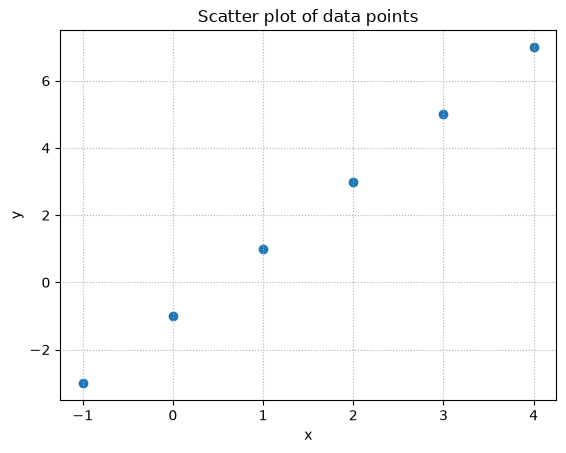

In [ ]:
plt.scatter(x,y)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Scatter plot of data points')
plt.grid(ls=":")
plt.show()

## Creating the model

In [14]:
model = keras.Sequential([
    keras.layers.Input(shape=(1,), dtype="float32"),
    keras.layers.Dense(units=1)
])

model.compile(optimizer="sgd", loss="mean_squared_error")

history = model.fit(x, y, epochs=500, verbose=1)

Epoch 1/500


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step - loss: 37.2747
Epoch 2/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 29.6697
Epoch 3/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 23.6795
Epoch 4/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 18.9597
Epoch 5/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 15.2396
Epoch 6/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - loss: 12.3062
Epoch 7/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 9.9918
Epoch 8/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 8.1646
Epoch 9/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 6.7208
Epoch 10/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 5.5788
Epoch 11/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - loss: 4.6744
Epoch 12/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 3.9569
Epoch 13/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 3.3868
Epoch 14/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 2.9325
Epoch 15/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 2.5697
Epoch 16/500
1/1 ━━━━━━━

### plotting the loss and getting metrics

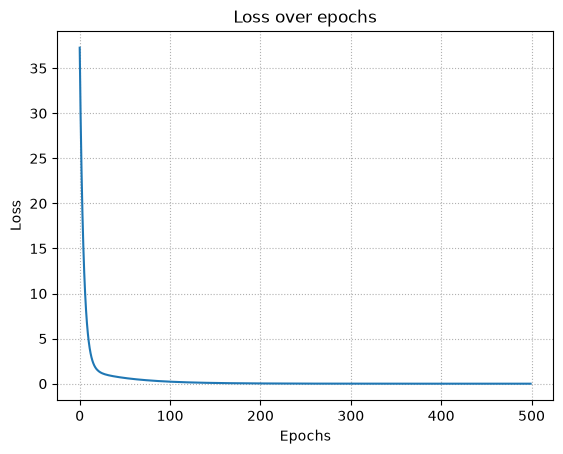

In [16]:
plt.plot(history.history["loss"])
#plt.plot(history.history["val_loss"], 'r--')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss over epochs")
plt.grid(ls=":")
plt.show()

In [24]:
# getting the R-squared value
y_pred = model.predict(x.reshape(-1, 1), verbose=0).reshape(-1)
ss_res = np.sum((y - y_pred) ** 2)
ss_tot = np.sum((y - np.mean(y)) ** 2)
r_squared = 1 - (ss_res / ss_tot)
print(f"R-squared: {r_squared:.4f}")


R-squared: 1.0000


In [27]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

mse = mean_squared_error(y, y_pred)
mae = mean_absolute_error(y, y_pred)

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")

Mean Squared Error (MSE): 0.0001
Mean Absolute Error (MAE): 0.0061


In [28]:
from sklearn.metrics import r2_score
r2 = r2_score(y, y_pred)
print(f"R-squared (using sklearn): {r2:.4f}")

R-squared (using sklearn): 1.0000


## Make predictions

In [26]:
x_test = 4
print(f"Prediction at x={x_test}:", model.predict(np.array([[x_test]], dtype=np.float32), verbose=0)[0, 0])

Prediction at x=4: 6.9971356
